**Name:** Vikrant Haral     
**Division:** E        
**Batch:** E1              
**Roll No.:** TY-319   
**PRN:** 202401040332


###**ASSIGNMENT 2**


---


A* Shortest Path and Map Coloring Using Backtracking




###**Aim:**
1. To find the shortest path between a source and destination using the A* search algorithm.
2. To solve the map-coloring problem using backtracking so that no two adjacent regions have the same color.

---

###**Theory**
1. **A\* Search:** A* selects the next node using \(f(n)=g(n)+h(n)\), where \(g(n)\) is the cost from the starting node and \(h(n)\) estimates the remaining cost. An admissible heuristic helps A* find an optimal path.
2. **Backtracking for Map Coloring:** The algorithm assigns colors to regions one at a time. If a color conflicts with an adjacent region, it tries another color. If no color works, it returns to an earlier region and changes its assignment.

---

###**Part 1: A star Shortest Path**

**Problem Statement:**

Find the shortest path between a source and destination in a grid using the A* search algorithm. The grid contains free cells and obstacles. The algorithm must avoid blocked cells and find the shortest possible route from the source to the destination. The grid uses four-directional movement: up, down, left, and right. Each move has a cost of 1, and Manhattan distance is used as the heuristic.

**Algorithm:**
1. Add the source node to the priority queue.
2. Select the node with the lowest \(f(n) = g(n) + h(n)\).
3. If it is the destination, reconstruct and return the path.
4. Otherwise, examine its valid neighboring cells and update their costs.
5. Repeat until the destination is reached or no path exists. The grid uses 4-directional movement (up, down, left, right). Each move costs 1, and Manhattan distance is used as the heuristic.

###**Code:**

A* SEARCH RESULT
Source: (0, 0)
Destination: (7, 7)
Shortest path: [(0, 0), (0, 1), (0, 2), (0, 3), (0, 4), (1, 4), (2, 4), (3, 4), (3, 5), (3, 6), (4, 6), (4, 7), (5, 7), (6, 7), (7, 7)]
Path length (moves): 14
Number of nodes expanded: 36


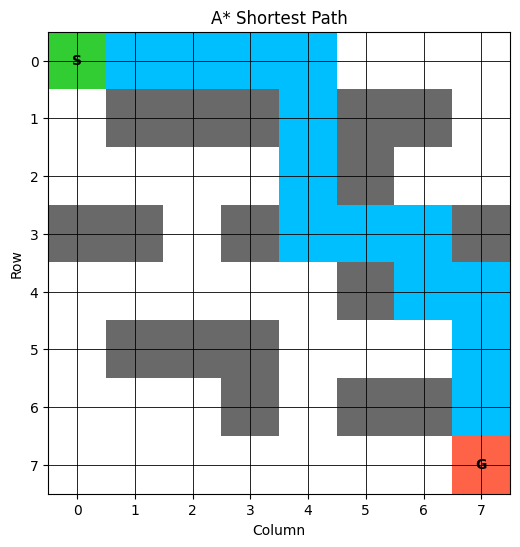

In [ ]:
import heapq
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from collections import deque

def astar(grid, start, goal):
    """Return (shortest_path, total_cost, expanded_nodes) using A*.

    grid: 2D list; 0 = free cell, 1 = obstacle
    start, goal: (row, column) tuples
    """
    rows, cols = len(grid), len(grid[0])

    def valid(cell):
        r, c = cell
        return 0 <= r < rows and 0 <= c < cols and grid[r][c] == 0

    def heuristic(cell):
        return abs(cell[0] - goal[0]) + abs(cell[1] - goal[1])

    if not valid(start) or not valid(goal):
        return [], float("inf"), 0

    frontier = [(heuristic(start), 0, start)]
    came_from = {start: None}
    g_cost = {start: 0}
    expanded = 0

    while frontier:
        _, current_cost, current = heapq.heappop(frontier)

        # Ignore outdated priority-queue entries
        if current_cost != g_cost.get(current, float("inf")):
            continue

        expanded += 1
        if current == goal:
            path = []
            node = goal
            while node is not None:
                path.append(node)
                node = came_from[node]
            path.reverse()
            return path, g_cost[goal], expanded

        r, c = current
        for neighbor in [(r-1,c), (r+1,c), (r,c-1), (r,c+1)]:
            if not valid(neighbor):
                continue

            tentative_g = g_cost[current] + 1
            if tentative_g < g_cost.get(neighbor, float("inf")):
                g_cost[neighbor] = tentative_g
                came_from[neighbor] = current
                heapq.heappush(
                    frontier,
                    (tentative_g + heuristic(neighbor), tentative_g, neighbor)
                )

    return [], float("inf"), expanded


def plot_grid_path(grid, path, start, goal, title="A* Shortest Path"):
    """Display obstacles, free cells, and the calculated path."""
    display = [row[:] for row in grid]
    for r, c in path:
        display[r][c] = 2
    display[start[0]][start[1]] = 3
    display[goal[0]][goal[1]] = 4

    cmap = ListedColormap(["white", "dimgray", "deepskyblue", "limegreen", "tomato"])
    plt.figure(figsize=(7, 6))
    plt.imshow(display, cmap=cmap, vmin=0, vmax=4)
    plt.xticks(range(len(grid[0])))
    plt.yticks(range(len(grid)))
    plt.grid(True, color="black", linewidth=0.6)
    plt.xlabel("Column")
    plt.ylabel("Row")
    plt.title(title)

    # Add labels for start and destination
    plt.text(start[1], start[0], "S", ha="center", va="center", fontweight="bold")
    plt.text(goal[1], goal[0], "G", ha="center", va="center", fontweight="bold")
    plt.show()


# Example grid: 0 = free cell, 1 = obstacle
grid = [
    [0,0,0,0,0,0,0,0],
    [0,1,1,1,0,1,1,0],
    [0,0,0,0,0,1,0,0],
    [1,1,0,1,0,0,0,1],
    [0,0,0,0,0,1,0,0],
    [0,1,1,1,0,0,0,0],
    [0,0,0,1,0,1,1,0],
    [0,0,0,0,0,0,0,0]
]

source = (0, 0)
destination = (7, 7)

path, cost, expanded_nodes = astar(grid, source, destination)

if path:
    print("A* SEARCH RESULT")
    print("Source:", source)
    print("Destination:", destination)
    print("Shortest path:", path)
    print("Path length (moves):", cost)
    print("Number of nodes expanded:", expanded_nodes)
    plot_grid_path(grid, path, source, destination)
else:
    print("No valid path exists between the source and destination.")

###**Part 2: Map Coloring using Backtracking**

**Problem Statement:**

Color each region of a map so that neighboring regions have different colors. This example uses a small illustrative map of regions. The adjacency graph is the problem input; it can be replaced with a graph for any map.

**Algorithm:**
1. Select the next uncolored region.
2. Try each available color.
3. Assign a color only if no already-colored neighboring region uses it.
4. Recursively color the remaining regions.
5. If no color works, undo the assignment (backtrack).
6. Stop when all regions are colored or no solution exists.

###**Code:**

MAP COLORING RESULT
North        -> red
West         -> green
Central      -> blue
East         -> green
Southwest    -> red
Southeast    -> yellow

Valid coloring: True
Number of regions: 6
Colors used: 4


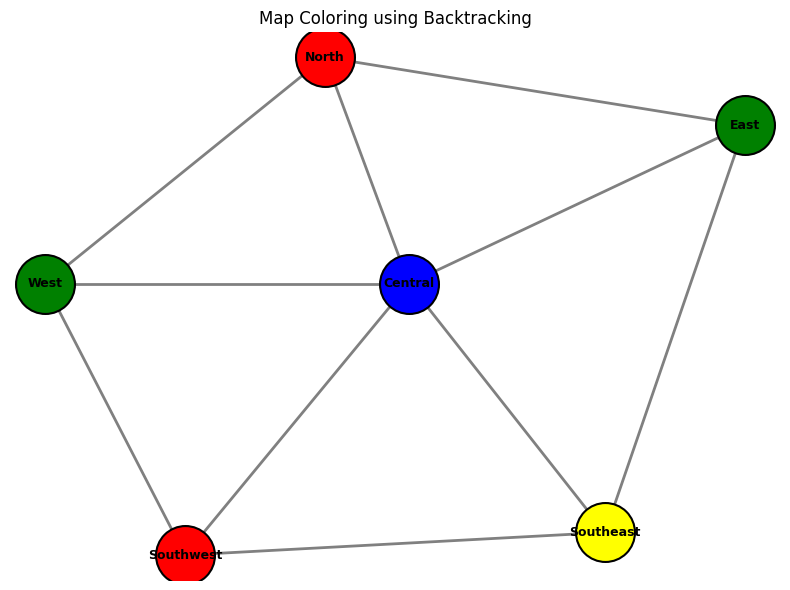

In [ ]:
def is_safe(region, color, assignment, graph):
    """Check that no already-colored neighbor has the proposed color."""
    for neighbor in graph[region]:
        if assignment.get(neighbor) == color:
            return False
    return True


def map_coloring_backtracking(graph, colors):
    """Return a valid region-to-color assignment, or None if impossible."""
    assignment = {}

    def backtrack():
        if len(assignment) == len(graph):
            return True

        # Choose the uncolored region with the most already-colored neighbors.
        # This is a useful heuristic; it does not change backtracking correctness.
        uncolored = [region for region in graph if region not in assignment]
        region = max(
            uncolored,
            key=lambda item: sum(neighbor in assignment for neighbor in graph[item])
        )

        for color in colors:
            if is_safe(region, color, assignment, graph):
                assignment[region] = color
                if backtrack():
                    return True
                del assignment[region]  # Backtrack

        return False

    return assignment if backtrack() else None


def validate_coloring(graph, assignment):
    """Return True only if every region is colored and all edges are valid."""
    if assignment is None or len(assignment) != len(graph):
        return False

    for region, neighbors in graph.items():
        for neighbor in neighbors:
            if assignment[region] == assignment[neighbor]:
                return False
    return True


def draw_colored_map(graph, assignment, positions):
    """Draw the region-adjacency graph using the assigned colors."""
    plt.figure(figsize=(8, 6))
    for region, neighbors in graph.items():
        x1, y1 = positions[region]
        for neighbor in neighbors:
            if region < neighbor:  # Draw each edge once
                x2, y2 = positions[neighbor]
                plt.plot([x1, x2], [y1, y2], color="gray", linewidth=2, zorder=1)

    for region, (x, y) in positions.items():
        plt.scatter(x, y, s=1800, color=assignment[region],
                    edgecolors="black", linewidths=1.5, zorder=2)
        plt.text(x, y, region, ha="center", va="center",
                 fontsize=9, fontweight="bold", zorder=3)

    plt.title("Map Coloring using Backtracking")
    plt.axis("off")
    plt.tight_layout()
    plt.show()


# Illustrative map represented as an undirected adjacency graph
# Each neighboring pair is listed in both directions.
graph = {
    "North": ["West", "Central", "East"],
    "West": ["North", "Central", "Southwest"],
    "Central": ["North", "West", "East", "Southwest", "Southeast"],
    "East": ["North", "Central", "Southeast"],
    "Southwest": ["West", "Central", "Southeast"],
    "Southeast": ["Central", "East", "Southwest"]
}

available_colors = ["red", "green", "blue", "yellow"]

color_assignment = map_coloring_backtracking(graph, available_colors)

print("MAP COLORING RESULT")
if color_assignment:
    for region, color in color_assignment.items():
        print(f"{region:12} -> {color}")
    print("\nValid coloring:", validate_coloring(graph, color_assignment))
    print("Number of regions:", len(color_assignment))
    print("Colors used:", len(set(color_assignment.values())))

    positions = {
        "North": (1.5, 3.0),
        "West": (0.5, 2.0),
        "Central": (1.8, 2.0),
        "East": (3.0, 2.7),
        "Southwest": (1.0, 0.8),
        "Southeast": (2.5, 0.9)
    }
    draw_colored_map(graph, color_assignment, positions)
else:
    print("No valid coloring exists with the available colors.")


**Test an impossible case:**

The following test creates a triangle (three regions, each adjacent to the other two). A triangle cannot be colored with only two colors, so the algorithm should report no solution.

In [ ]:
triangle_graph = {
    "A": ["B", "C"],
    "B": ["A", "C"],
    "C": ["A", "B"]
}

two_colors = ["red", "blue"]

triangle_result = map_coloring_backtracking(
    triangle_graph, two_colors
)

print("Triangle graph with two colors:", triangle_result)
print("Expected result: None (no valid coloring)")

Triangle graph with two colors: None
Expected result: None (no valid coloring)


###**Results and Conclusion:**
**Result 1:** The A* algorithm searches the grid and returns a shortest path from the source to the destination while avoiding blocked cells. The path length is reported as the number of moves, and the plotted grid shows the route.

**Result 2:** The backtracking algorithm assigns colors to regions while ensuring that adjacent regions have different colors. The validation function checks the final assignment, and the impossible triangle test demonstrates that the algorithm can detect when the available colors are insufficient.

**Conclusion:** Both tasks were implemented in Python and visualized in Google Colab. A* uses path cost and a heuristic to guide search, while backtracking explores valid color assignments and reverses choices when a conflict prevents a solution.